# Hypothesis Test Selection Flowchart

Choosing the right statistical test is a sequence of questions about your data. This lesson turns those questions into a **flowchart** and then into an **R function** that recommends a test automatically.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. The Questions to Ask

1. **What type is the outcome?**
   - Categorical (counts) → $\chi^2$ test (or Fisher's exact test when expected counts are small, < 5)
   - Numeric (measurements) → continue
2. **How many groups are you comparing?** One (vs a reference value), two, or three or more.
3. **Are the observations paired / repeated?** The same subjects measured twice (before/after) or under several conditions.
4. **Is the normality assumption reasonable?** (Lesson 16: Shapiro–Wilk, Q–Q plots; with large samples the CLT helps.)
   - Yes → **parametric** test (t-test, ANOVA)
   - No → **non-parametric**, rank-based test (Wilcoxon, Mann–Whitney, Kruskal–Wallis, Friedman)
5. **Are the variances equal?** (Levene's test.) If not → **Welch** versions (Welch t-test, Welch ANOVA).
6. If a test on 3+ groups is significant → **post-hoc** comparisons (Lesson 17).

## 2. Drawing the Flowchart in Base R

The flowchart is drawn with plain base-R graphics (`rect`, `text`, `arrows`), so it needs **no extra packages**. Each node has a parent; leaves are spaced evenly and each parent is centred above its children.

> The same diagram can also be drawn with `DiagrammeR::grViz()` (Graphviz syntax), but that package needs system libraries (`librsvg`, `libcurl`) that aren't available on every machine.

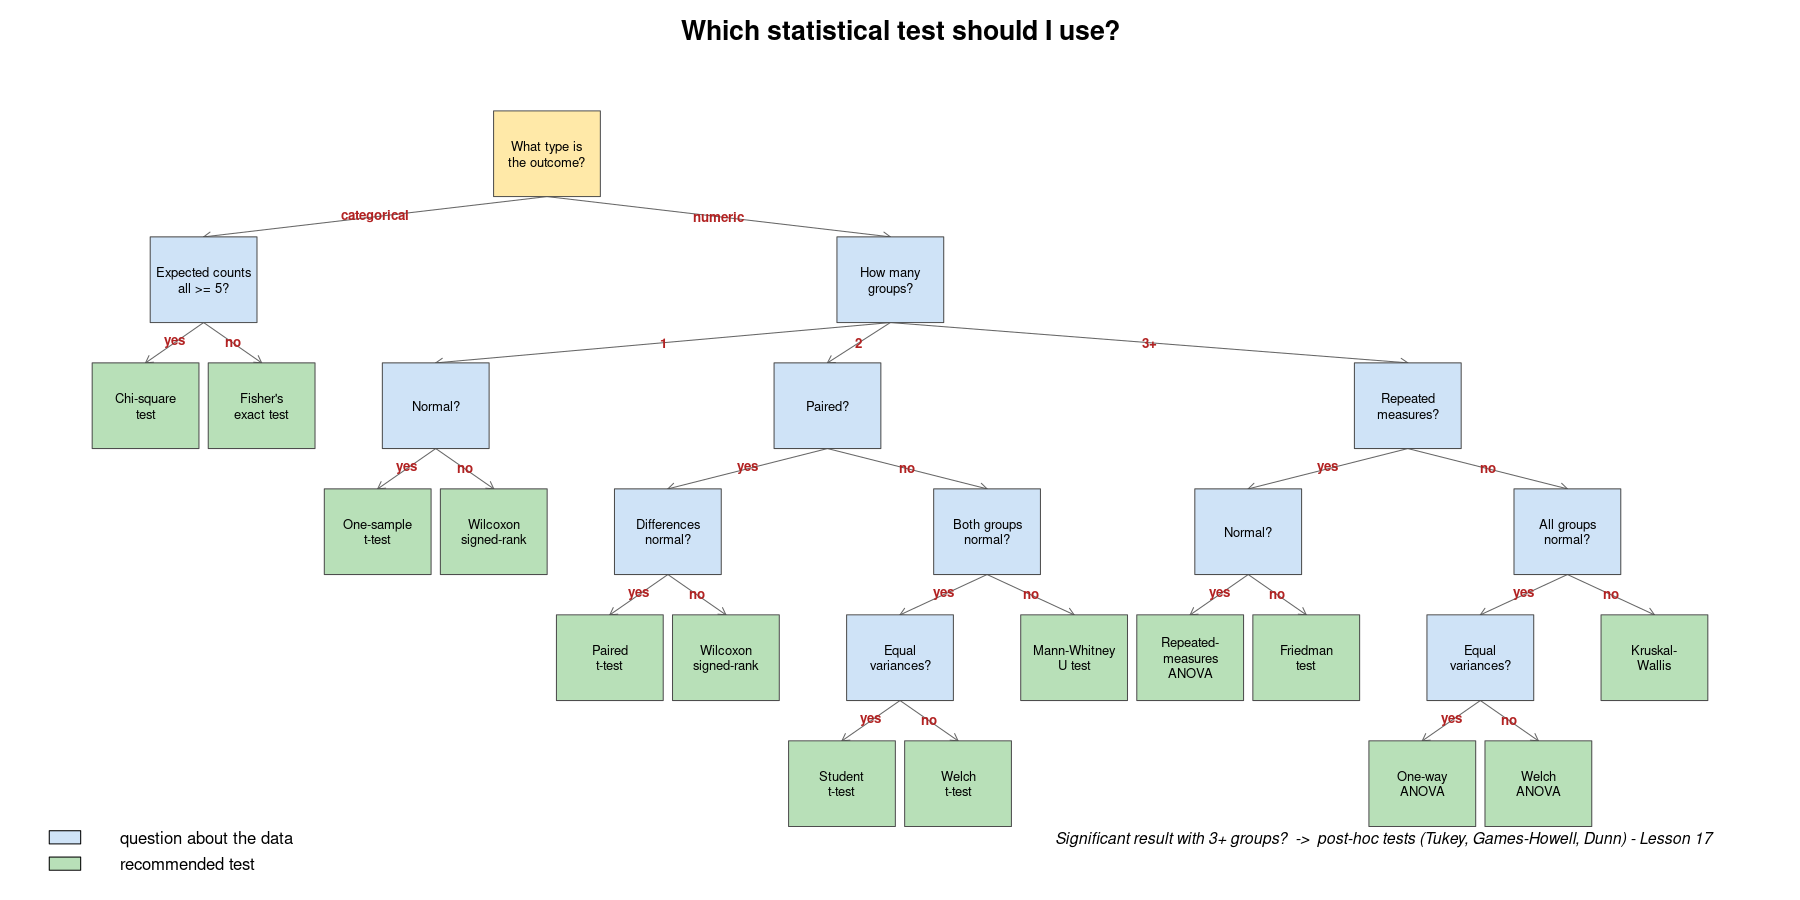

In [2]:
# Each row: id, parent, label shown in the box (~ = line break), edge label from the parent
nodes <- read.table(header = TRUE, sep = "|", strip.white = TRUE, quote = "", fill = TRUE,
                    comment.char = "", text = "
id     | parent | label                                  | edge
root   | NA     | What type is~the outcome?              |
cnt    | root   | Expected counts~all >= 5?              | categorical
chi    | cnt    | Chi-square~test                        | yes
fish   | cnt    | Fisher's~exact test                    | no
grp    | root   | How many~groups?                       | numeric
n1     | grp    | Normal?                                 | 1
t1     | n1     | One-sample~t-test                      | yes
w1     | n1     | Wilcoxon~signed-rank                   | no
pair2  | grp    | Paired?                                 | 2
np2    | pair2  | Differences~normal?                    | yes
tp     | np2    | Paired~t-test                          | yes
wsr    | np2    | Wilcoxon~signed-rank                   | no
ni2    | pair2  | Both groups~normal?                    | no
ev2    | ni2    | Equal~variances?                       | yes
st     | ev2    | Student~t-test                         | yes
wt     | ev2    | Welch~t-test                           | no
mw     | ni2    | Mann-Whitney~U test                    | no
rep3   | grp    | Repeated~measures?                     | 3+
nr3    | rep3   | Normal?                                 | yes
rma    | nr3    | Repeated-~measures~ANOVA              | yes
fr     | nr3    | Friedman~test                          | no
ni3    | rep3   | All groups~normal?                     | no
ev3    | ni3    | Equal~variances?                       | yes
aov1   | ev3    | One-way~ANOVA                          | yes
wa     | ev3    | Welch~ANOVA                            | no
kw     | ni3    | Kruskal-~Wallis                        | no
")
nodes$label  <- gsub("~", "\n", nodes$label, fixed = TRUE)   # "~" marks a line break
nodes$parent[nodes$parent == "NA"] <- NA
nodes$edge[is.na(nodes$edge)] <- ""

# Layout: leaves get consecutive x positions, parents sit above the mean of their children
children <- function(id) nodes$id[!is.na(nodes$parent) & nodes$parent == id]
depth <- function(id) { d <- 0; p <- nodes$parent[nodes$id == id]; while (!is.na(p)) { d <- d + 1; p <- nodes$parent[nodes$id == p] }; d }
nodes$depth <- sapply(nodes$id, depth)
nodes$x <- NA; next_leaf <- 0
place <- function(id) {
  ch <- children(id)
  if (length(ch) == 0) { next_leaf <<- next_leaf + 1; x <- next_leaf }
  else x <- mean(sapply(ch, place))
  nodes$x[nodes$id == id] <<- x
  x
}
invisible(place("root"))
nodes$y <- -nodes$depth
nodes$leaf <- sapply(nodes$id, function(i) length(children(i)) == 0)

draw_flowchart <- function() {
  par(mar = c(0.5, 0.5, 3, 0.5))
  plot(NA, xlim = c(0.4, max(nodes$x) + 0.6), ylim = c(min(nodes$y) - 0.6, 0.5), axes = FALSE,
       xlab = "", ylab = "", main = "Which statistical test should I use?", cex.main = 1.6)
  bw <- 0.46; bh <- 0.34
  for (i in which(!is.na(nodes$parent))) {
    p <- match(nodes$parent[i], nodes$id)
    arrows(nodes$x[p], nodes$y[p] - bh, nodes$x[i], nodes$y[i] + bh, length = 0.08, col = "grey40")
    text((nodes$x[p] + nodes$x[i]) / 2, (nodes$y[p] + nodes$y[i]) / 2, nodes$edge[i],
         cex = 0.8, col = "firebrick", font = 2)
  }
  fill <- ifelse(nodes$id == "root", "#FFE9A8", ifelse(nodes$leaf, "#B8E0B8", "#CFE3F7"))
  rect(nodes$x - bw, nodes$y - bh, nodes$x + bw, nodes$y + bh, col = fill, border = "grey30")
  text(nodes$x, nodes$y, nodes$label, cex = 0.78)
  legend("bottomleft", bty = "n", fill = c("#CFE3F7", "#B8E0B8"), cex = 1,
         legend = c("question about the data", "recommended test"))
  text(max(nodes$x) + 0.5, min(nodes$y) - 0.45, adj = 1, cex = 0.95, font = 3,
       "Significant result with 3+ groups?  ->  post-hoc tests (Tukey, Games-Howell, Dunn) - Lesson 17")
}

options(repr.plot.width = 18, repr.plot.height = 9)
draw_flowchart()

# Also save the chart as a PNG next to the notebook (referenced in the markdown cell below)
png("test_selection_flow.png", width = 1800, height = 900, res = 100, bg = "white")
draw_flowchart()
invisible(dev.off())
options(repr.plot.width = 10, repr.plot.height = 6)

The same chart is saved as `test_selection_flow.png`, so you can embed it in your own notes:

![Test selection flowchart](test_selection_flow.png)

## 3. Turning the Flowchart Into Code

The function below asks the same questions **of the data itself**: it checks normality with Shapiro–Wilk and equal variances with Bartlett's test, then recommends — and runs — a test.

*(Automated assumption tests are a teaching aid. In real analyses, also look at plots and think about the study design: small samples give normality tests little power, and huge samples flag trivial deviations.)*

In [3]:
choose_test <- function(values, groups = NULL, paired = FALSE, alpha = 0.05) {
  is_normal <- function(x) length(x) >= 3 && shapiro.test(x)$p.value > alpha

  if (is.null(groups)) {
    name <- if (is_normal(values)) "One-sample t-test" else "Wilcoxon signed-rank test"
    return(name)
  }
  groups <- droplevels(factor(groups))
  k <- nlevels(groups)
  split_vals <- split(values, groups)

  if (k == 2 && paired) {
    d <- split_vals[[1]] - split_vals[[2]]
    return(if (is_normal(d)) "Paired t-test" else "Wilcoxon signed-rank test")
  }
  all_normal <- all(sapply(split_vals, is_normal))
  if (k == 2) {
    if (!all_normal) return("Mann-Whitney U test")
    return(if (bartlett.test(values, groups)$p.value > alpha) "Student t-test" else "Welch t-test")
  }
  if (paired) return(if (all_normal) "Repeated-measures ANOVA" else "Friedman test")
  if (!all_normal) return("Kruskal-Wallis test")
  if (bartlett.test(values, groups)$p.value > alpha) "One-way ANOVA" else "Welch ANOVA"
}

In [4]:
set.seed(13)
scenarios <- list(
  "Normal, 2 groups, equal SD"   = list(v = c(rnorm(30, 50, 5),  rnorm(30, 54, 5)),  g = rep(c("a", "b"), each = 30)),
  "Normal, 2 groups, unequal SD" = list(v = c(rnorm(30, 50, 2),  rnorm(30, 54, 10)), g = rep(c("a", "b"), each = 30)),
  "Skewed, 2 groups"             = list(v = c(rexp(30, 0.2), rexp(30, 0.1)),         g = rep(c("a", "b"), each = 30)),
  "Normal, 3 groups, equal SD"   = list(v = c(rnorm(25, 10, 2), rnorm(25, 11, 2), rnorm(25, 12, 2)), g = rep(c("a", "b", "c"), each = 25)),
  "Skewed, 3 groups"             = list(v = c(rexp(25, 1), rexp(25, 0.7), rexp(25, 0.5)), g = rep(c("a", "b", "c"), each = 25))
)

result <- data.frame(scenario = names(scenarios),
                     recommended = sapply(scenarios, function(s) choose_test(s$v, s$g)),
                     row.names = NULL)
print(result, right = FALSE)

# Run the recommended test for the skewed 2-group case
s <- scenarios[["Skewed, 2 groups"]]
wilcox.test(s$v ~ s$g)

  scenario                     recommended        
1 Normal, 2 groups, equal SD   Student t-test     
2 Normal, 2 groups, unequal SD Welch t-test       
3 Skewed, 2 groups             Mann-Whitney U test
4 Normal, 3 groups, equal SD   One-way ANOVA      
5 Skewed, 3 groups             Kruskal-Wallis test



	Wilcoxon rank sum exact test

data:  s$v by s$g
W = 298, p-value = 0.02434
alternative hypothesis: true location shift is not equal to 0


*Insight: The two most common mistakes are (1) using a Student t-test when the group variances differ — the **Welch** t-test is the safer default and is what `t.test()` does unless you set `var.equal = TRUE`; and (2) treating paired data as independent, which throws away information and lowers power.*

## Real-World Use Case or Analogy

Choosing a test is like a **doctor's triage**:

- First question: *what kind of problem is it?* (categorical vs numeric outcome)
- Then: *how many patients/conditions are involved?* (number of groups)
- Then: *is it the same patient measured twice?* (paired vs independent)
- Then: *do the standard assumptions hold?* (normal → standard treatment = parametric test; otherwise the robust alternative = non-parametric test)

Following the flowchart is like following a clinical guideline: it doesn't replace judgement, but it prevents the most common — and most avoidable — mistakes.